# Module 4 — Computer Vision : Détection et Évaluation des Dommages Auto

**Objectif** : détecter et localiser les dégâts sur un véhicule à partir d'une photo,
estimer la sévérité (Minor / Moderate / Severe / Total Loss) et produire une
estimation du coût de réparation — intégrable dans le backend FastAPI de SIAP.

**Dataset** : car-damage by Skillfactory (Roboflow Universe)
- 8 857 images annotées avec bounding boxes
- 31 classes de dégâts (scratch, dent, damaged-door, front-bumper-dent, etc.)
- License CC BY 4.0

**Modèle** : YOLOv8n (fine-tuning depuis MS COCO)
- State-of-the-art détection d'objets
- Léger (Nano) → déployable en production
- mAP@50 baseline Roboflow : 57.2% → objectif après fine-tuning : > 60%

**Pipeline** :
1. Téléchargement dataset via API Roboflow
2. Fine-tuning YOLOv8n (50 epochs, GPU Colab T4)
3. Évaluation : mAP@50, précision, rappel par classe
4. Mapping actuariel : classes → sévérité → coût estimé
5. Pipeline complet : image → dégâts détectés → rapport sinistre
6. Connexion Module 2 : cohérence photo / déclaration → alerte fraude
7. Export artifacts pour FastAPI

## Bloc 1 — Setup

**IMPORTANT** : avant d'exécuter ce bloc, vérifier que le GPU est activé :
Colab → Exécution → Modifier le type d'exécution → GPU (T4)
Sans GPU, l'entraînement YOLOv8 prendra 10x plus de temps.

In [1]:
# ============================================================
# SETUP
# ============================================================
!pip install ultralytics roboflow -q

import os
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

from ultralytics import YOLO
import torch

print(f"PyTorch version : {torch.__version__}")
print(f"GPU disponible  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
else:
    print("WARNING : pas de GPU détecté. Activer GPU dans Colab avant de continuer.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 63.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch version : 2.11.0+cu128
GPU disponible  : True
GPU             : Tesla T4


## Bloc 2 — Téléchargement du dataset

In [2]:
# ============================================================
# TÉLÉCHARGEMENT DU DATASET ROBOFLOW
# ============================================================
from roboflow import Roboflow

rf = Roboflow(api_key="yP2wQtlylK9kSVOV1V2R")
project = rf.workspace("selmis-workspace-ug9bs").project("car-damage-c1f0i-ejfk3")
version = project.version(1)
dataset = version.download("yolov8")

DATASET_PATH = dataset.location
print(f"Dataset téléchargé dans : {DATASET_PATH}")

# Vérification de la structure
for split in ['train', 'valid', 'test']:
    img_dir = Path(DATASET_PATH) / split / 'images'
    lbl_dir = Path(DATASET_PATH) / split / 'labels'
    if img_dir.exists():
        n_imgs = len(list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png')))
        print(f"{split:6} : {n_imgs} images")

# Lire le fichier data.yaml pour récupérer les classes
import yaml
with open(Path(DATASET_PATH) / 'data.yaml') as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config['names']
print(f"\nNombre de classes : {len(CLASS_NAMES)}")
print(f"Classes : {CLASS_NAMES}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to car-damage-1 in yolov8:: 100%|██████████| 17719/17719 [00:05<00:00, 3036.58it/s]


Dataset téléchargé dans : /content/car-damage-1
train  : 6365 images
valid  : 2027 images
test   : 465 images

Nombre de classes : 31
Classes : ['Front-Windscreen-Damage', 'Headlight-Damage', 'Major-Rear-Bumper-Dent', 'Rear-windscreen-Damage', 'RunningBoard-Dent', 'Sidemirror-Damage', 'Signlight-Damage', 'Taillight-Damage', 'bonnet-dent', 'damaged', 'damaged-door', 'damaged-front-bumper', 'damaged-head-light', 'damaged-hood', 'damaged-rear-bumper', 'damaged-rear-window', 'damaged-tail-light', 'damaged-trunk', 'damaged-window', 'damaged-windscreen', 'dent', 'dent-or-scratch', 'doorouter-dent', 'fender-dent', 'front-bumper-dent', 'medium-Bodypanel-Dent', 'pillar-dent', 'quaterpanel-dent', 'rear-bumper-dent', 'roof-dent', 'scratch']


## Bloc 3 — EDA : visualisation du dataset

Avant d'entraîner, on analyse la distribution des classes pour détecter
d'éventuels déséquilibres qui pourraient biaiser le modèle.

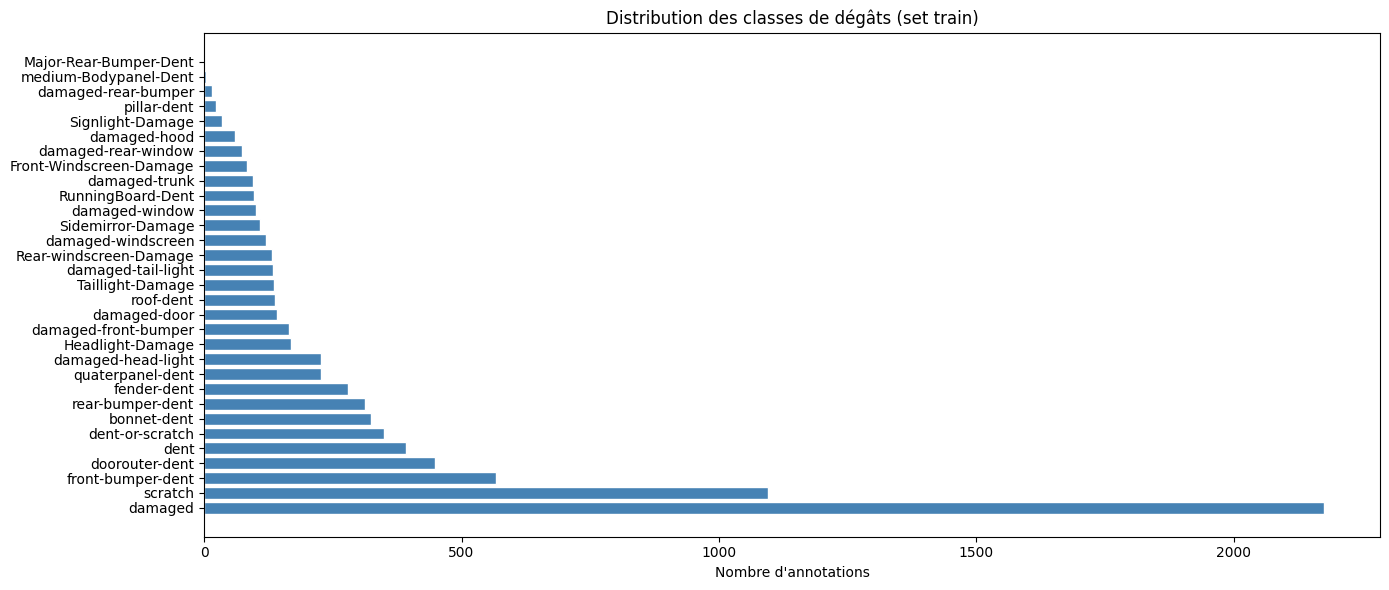


Top 5 classes les plus fréquentes :
  damaged                        : 2175 annotations
  scratch                        : 1096 annotations
  front-bumper-dent              : 566 annotations
  doorouter-dent                 : 449 annotations
  dent                           : 392 annotations

Classes avec < 50 annotations (risque de sous-représentation) :
  Signlight-Damage               : 34 annotations
  pillar-dent                    : 24 annotations
  damaged-rear-bumper            : 16 annotations
  medium-Bodypanel-Dent          : 3 annotations
  Major-Rear-Bumper-Dent         : 1 annotations


In [3]:
# Distribution des classes dans le set d'entraînement
from collections import Counter

label_dir = Path(DATASET_PATH) / 'train' / 'labels'
class_counts = Counter()

for label_file in label_dir.glob('*.txt'):
    with open(label_file) as f:
        for line in f:
            class_id = int(line.strip().split()[0])
            class_counts[class_id] += 1

# Trier par fréquence
sorted_counts = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
class_labels = [CLASS_NAMES[i] for i, _ in sorted_counts]
counts = [c for _, c in sorted_counts]

plt.figure(figsize=(14, 6))
bars = plt.barh(class_labels, counts, color='steelblue', edgecolor='white')
plt.xlabel('Nombre d\'annotations')
plt.title('Distribution des classes de dégâts (set train)')
plt.tight_layout()
plt.show()

print(f"\nTop 5 classes les plus fréquentes :")
for cls_id, count in sorted_counts[:5]:
    print(f"  {CLASS_NAMES[cls_id]:30} : {count} annotations")

print(f"\nClasses avec < 50 annotations (risque de sous-représentation) :")
for cls_id, count in sorted_counts:
    if count < 50:
        print(f"  {CLASS_NAMES[cls_id]:30} : {count} annotations")

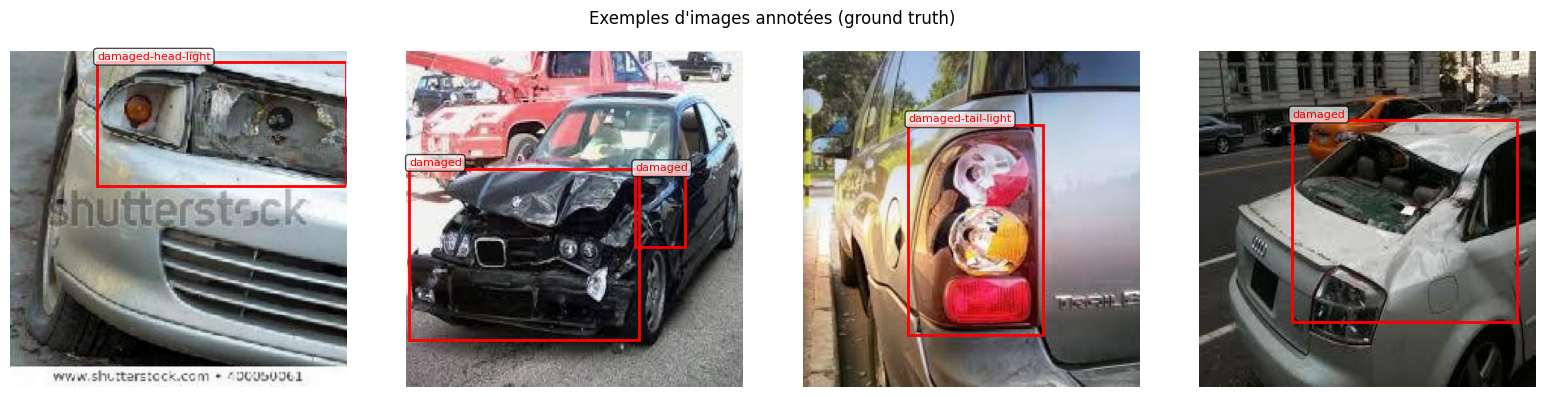

In [4]:
# Visualiser quelques images annotées
def show_annotated_sample(img_dir, label_dir, class_names, n=4):
    img_files = list(img_dir.glob('*.jpg'))[:n]
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))

    for ax, img_file in zip(axes, img_files):
        img = Image.open(img_file).convert('RGB')
        w, h = img.size
        ax.imshow(img)

        label_file = label_dir / (img_file.stem + '.txt')
        if label_file.exists():
            with open(label_file) as f:
                for line in f:
                    parts = line.strip().split()
                    cls_id = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:5])
                    x1 = (cx - bw/2) * w
                    y1 = (cy - bh/2) * h
                    rect = patches.Rectangle(
                        (x1, y1), bw*w, bh*h,
                        linewidth=2, edgecolor='red', facecolor='none'
                    )
                    ax.add_patch(rect)
                    ax.text(x1, y1-5, class_names[cls_id],
                            color='red', fontsize=8,
                            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
        ax.axis('off')

    plt.suptitle('Exemples d\'images annotées (ground truth)', fontsize=12)
    plt.tight_layout()
    plt.show()

show_annotated_sample(
    Path(DATASET_PATH) / 'train' / 'images',
    Path(DATASET_PATH) / 'train' / 'labels',
    CLASS_NAMES
)

## Bloc 4 — Fine-tuning YOLOv8n

On part du modèle YOLOv8n pré-entraîné sur MS COCO (80 classes génériques)
et on le fine-tune sur notre dataset de dégâts auto (31 classes spécifiques).

**Paramètres** :
- `epochs=50` : bon compromis qualité/temps sur Colab T4 gratuit (~45 min)
- `imgsz=640` : résolution standard YOLOv8
- `batch=16` : adapté à la mémoire GPU T4 (16 GB)
- `patience=15` : early stopping si pas d'amélioration pendant 15 epochs
- `pretrained=True` : partir des poids COCO (transfer learning)

In [5]:
# ============================================================
# FINE-TUNING YOLOV8
# ============================================================
# Charger le modèle pré-entraîné YOLOv8 Nano
model = YOLO('yolov8n.pt')

# Lancer l'entraînement
results = model.train(
    data=str(Path(DATASET_PATH) / 'data.yaml'),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    pretrained=True,
    optimizer='AdamW',
    lr0=0.001,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3,
    augment=True,
    degrees=10.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    project='siap_cv',
    name='car_damage_v1',
    exist_ok=True,
    verbose=True
)

print("\nEntraînement terminé.")
print(f"Meilleur modèle sauvegardé dans : siap_cv/car_damage_v1/weights/best.pt")

Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/car-damage-1/data.yaml, degrees=10.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=car_damage_v1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, pa

## Bloc 5 — Évaluation

On évalue le modèle sur le set de test (jamais vu pendant l'entraînement).

**Métriques clés** :
- **mAP@50** : précision moyenne à seuil IoU=0.5 (métrique principale)
- **Précision** : parmi les détections, combien sont correctes
- **Rappel** : parmi les vrais dégâts, combien sont détectés

**Cibles** :
- mAP@50 > 57.2% (dépasser le baseline Roboflow)
- Rappel > 55% (ne pas rater trop de dégâts réels)

In [6]:
# Charger le meilleur modèle
best_model = YOLO('/content/runs/detect/siap_cv/car_damage_v1/weights/best.pt')
# Évaluation sur le set de test
metrics = best_model.val(
    data=str(Path(DATASET_PATH) / 'data.yaml'),
    split='test',
    imgsz=640,
    conf=0.25,
    iou=0.45
)

map50 = metrics.box.map50
map50_95 = metrics.box.map
precision = metrics.box.mp
recall = metrics.box.mr

print("=" * 50)
print("MÉTRIQUES GLOBALES — Set de test")
print("=" * 50)
print(f"mAP@50       : {map50:.4f} ({map50*100:.1f}%)")
print(f"mAP@50-95    : {map50_95:.4f} ({map50_95*100:.1f}%)")
print(f"Précision    : {precision:.4f} ({precision*100:.1f}%)")
print(f"Rappel       : {recall:.4f} ({recall*100:.1f}%)")
print()

# Validation actuarielle
checks = {
    f'mAP@50 > 57.2% (baseline Roboflow)': map50 > 0.572,
    f'Rappel > 50%': recall > 0.50,
    f'Précision > 55%': precision > 0.55,
}
for check, result in checks.items():
    print(f"{'oui' if result else 'non'} {check}")

Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,693 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1104.1±385.5 MB/s, size: 114.7 KB)
val: Scanning /content/car-damage-1/test/labels... 465 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 465/465 1.3Kit/s 0.4s
val: New cache created: /content/car-damage-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 2.9it/s 10.5s
                   all        465        657      0.773      0.629      0.599      0.371
Front-Windscreen-Damage         15         15          1      0.467      0.465      0.296
      Headlight-Damage         22         22        0.8      0.909      0.861      0.541
Rear-windscreen-Damage         24         24        0.8      0.833       0.76      0.593
     RunningBoard-Dent         18         28       0.25     0.0714     0.0

In [7]:
# mAP par classe
per_class_ap = metrics.box.ap50

class_perf = pd.DataFrame({
    'class': CLASS_NAMES[:len(per_class_ap)],
    'ap50': per_class_ap
}).sort_values('ap50', ascending=False)

print("AP@50 par classe (top 15) :")
print(class_perf.head(15).to_string(index=False))

print(f"\nClasses avec AP@50 < 30% (détection difficile) :")
weak_classes = class_perf[class_perf['ap50'] < 0.30]
print(weak_classes.to_string(index=False) if len(weak_classes) > 0 else "Aucune")

AP@50 par classe (top 15) :
                  class     ap50
       Headlight-Damage 0.860626
    damaged-rear-window 0.819014
            bonnet-dent 0.762949
 Major-Rear-Bumper-Dent 0.759714
       Signlight-Damage 0.685000
                damaged 0.684210
       Taillight-Damage 0.675620
     damaged-head-light 0.664322
      RunningBoard-Dent 0.653978
           damaged-hood 0.614700
   damaged-front-bumper 0.597861
           damaged-door 0.588833
Front-Windscreen-Damage 0.465000
    damaged-rear-bumper 0.383889
      Sidemirror-Damage 0.335000

Classes avec AP@50 < 30% (détection difficile) :
                 class     ap50
Rear-windscreen-Damage 0.030833


## Bloc 6 — Mapping actuariel

On définit le mapping entre les 31 classes YOLO et les 4 niveaux de sévérité
actuariels, puis les fourchettes de coût calibrées sur la sévérité moyenne
du Module 1 (2 279€ pour de l'auto).

In [8]:
# ============================================================
# MAPPING ACTUARIEL : classe YOLO → sévérité → coût
# ============================================================

SEVERITY_MAPPING = {
    # ── MINOR (réparation sans remplacement de pièce) ──────
    'scratch':              'Minor',
    'dent':                 'Minor',
    'dent-or-scratch':      'Minor',
    'Sidemirror-Damage':    'Minor',
    'Signlight-Damage':     'Minor',
    'medium-Bodypanel-Dent':'Minor',

    # ── MODERATE (remplacement de pièce nécessaire) ─────────
    'damaged-door':         'Moderate',
    'damaged-front-bumper': 'Moderate',
    'damaged-rear-bumper':  'Moderate',
    'front-bumper-dent':    'Moderate',
    'rear-bumper-dent':     'Moderate',
    'doorouter-dent':       'Moderate',
    'fender-dent':          'Moderate',
    'bonnet-dent':          'Moderate',
    'Headlight-Damage':     'Moderate',
    'Taillight-Damage':     'Moderate',
    'roof-dent':            'Moderate',
    'quaterpanel-dent':     'Moderate',
    'pillar-dent':          'Moderate',
    'RunningBoard-Dent':    'Moderate',
    'Major-Rear-Bumper-Dent':'Moderate',

    # ── SEVERE (réparation structurelle) ────────────────────
    'damaged-hood':         'Severe',
    'damaged-trunk':        'Severe',
    'damaged-window':       'Severe',
    'damaged-windscreen':   'Severe',
    'Front-Windscreen-Damage':'Severe',
    'Rear-windscreen-Damage':'Severe',
    'damaged-rear-window':  'Severe',
    'damaged-head-light':   'Severe',
    'damaged-tail-light':   'Severe',

    # ── TOTAL LOSS ──────────────────────────────────────────
    'damaged':              'Total Loss',
}

# Fourchettes de coût calibrées sur sévérité Module 1 (mean = 2 279€)
# La sévérité moyenne étant pour un sinistre moyen (mostly Moderate),
# on calibre autour de ce point central.
COST_ESTIMATE = {
    'Minor':      {'min': 150,   'central': 600,   'max': 1500,  'currency': 'EUR'},
    'Moderate':   {'min': 1200,  'central': 3500,  'max': 7000,  'currency': 'EUR'},
    'Severe':     {'min': 5000,  'central': 12000, 'max': 20000, 'currency': 'EUR'},
    'Total Loss': {'min': 15000, 'central': 25000, 'max': 50000, 'currency': 'EUR'},
}

# Vérification : toutes les classes du dataset sont mappées ?
unmapped = [c for c in CLASS_NAMES if c not in SEVERITY_MAPPING]
if unmapped:
    print(f"  Classes non mappées (à ajouter manuellement) : {unmapped}")
    # Fallback : mapper les classes inconnues à 'Moderate'
    for c in unmapped:
        SEVERITY_MAPPING[c] = 'Moderate'
    print(f"   → Mappées à 'Moderate' par défaut")
else:
    print(f" Toutes les {len(CLASS_NAMES)} classes sont mappées")

# Afficher la distribution des sévérités
from collections import Counter
sev_dist = Counter(SEVERITY_MAPPING.values())
print(f"\nDistribution des sévérités :")
for sev, count in sorted(sev_dist.items()):
    print(f"  {sev:12} : {count} classes")

 Toutes les 31 classes sont mappées

Distribution des sévérités :
  Minor        : 6 classes
  Moderate     : 15 classes
  Severe       : 9 classes
  Total Loss   : 1 classes


## Bloc 7 — Pipeline complet d'analyse

Le pipeline qu'exposera l'API FastAPI :
1. Recevoir une image
2. Détecter les dégâts avec YOLOv8
3. Mapper les classes détectées vers les niveaux de sévérité
4. Calculer la sévérité globale (worst case)
5. Estimer le coût
6. Retourner le rapport complet + image annotée

In [9]:
import base64
from io import BytesIO

SEVERITY_ORDER = {'Minor': 1, 'Moderate': 2, 'Severe': 3, 'Total Loss': 4}

def analyze_vehicle_damage(image_path: str, conf_threshold: float = 0.25) -> dict:
    """
    Pipeline complet d'analyse des dommages.

    Args:
        image_path  : chemin vers l'image du véhicule
        conf_threshold : seuil de confiance pour les détections

    Returns:
        dict avec toutes les informations actuarielles
    """
    # ── 1. Inférence YOLO ──────────────────────────────────
    results = best_model.predict(
        source=image_path,
        conf=conf_threshold,
        iou=0.45,
        imgsz=640,
        verbose=False
    )
    result = results[0]

    # ── 2. Extraire les détections ─────────────────────────
    detections = []
    for box in result.boxes:
        cls_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = CLASS_NAMES[cls_id]
        severity = SEVERITY_MAPPING.get(class_name, 'Moderate')
        bbox = box.xyxy[0].tolist()  # [x1, y1, x2, y2]

        detections.append({
            'class_name': class_name,
            'confidence': round(confidence, 3),
            'severity': severity,
            'bbox': [round(v, 1) for v in bbox]
        })

    # ── 3. Sévérité globale (worst case actuariel) ──────────
    if not detections:
        overall_severity = 'No Damage Detected'
        cost_estimate = {'min': 0, 'central': 0, 'max': 0, 'currency': 'EUR'}
    else:
        worst_severity = max(
            detections,
            key=lambda d: SEVERITY_ORDER.get(d['severity'], 0)
        )['severity']
        overall_severity = worst_severity
        cost_estimate = COST_ESTIMATE[worst_severity]

    # ── 4. Image annotée (base64 pour l'API) ────────────────
    annotated_img = result.plot()
    annotated_pil = Image.fromarray(annotated_img[..., ::-1])  # BGR → RGB
    buffer = BytesIO()
    annotated_pil.save(buffer, format='JPEG', quality=85)
    annotated_b64 = base64.b64encode(buffer.getvalue()).decode('utf-8')

    return {
        'damage_detected': len(detections) > 0,
        'n_damage_zones': len(detections),
        'detections': detections,
        'overall_severity': overall_severity,
        'cost_estimate': cost_estimate,
        'confidence_avg': round(
            sum(d['confidence'] for d in detections) / len(detections), 3
        ) if detections else 0.0,
        'annotated_image_b64': annotated_b64,
    }

print("Pipeline analyze_vehicle_damage() défini.")

Pipeline analyze_vehicle_damage() défini.


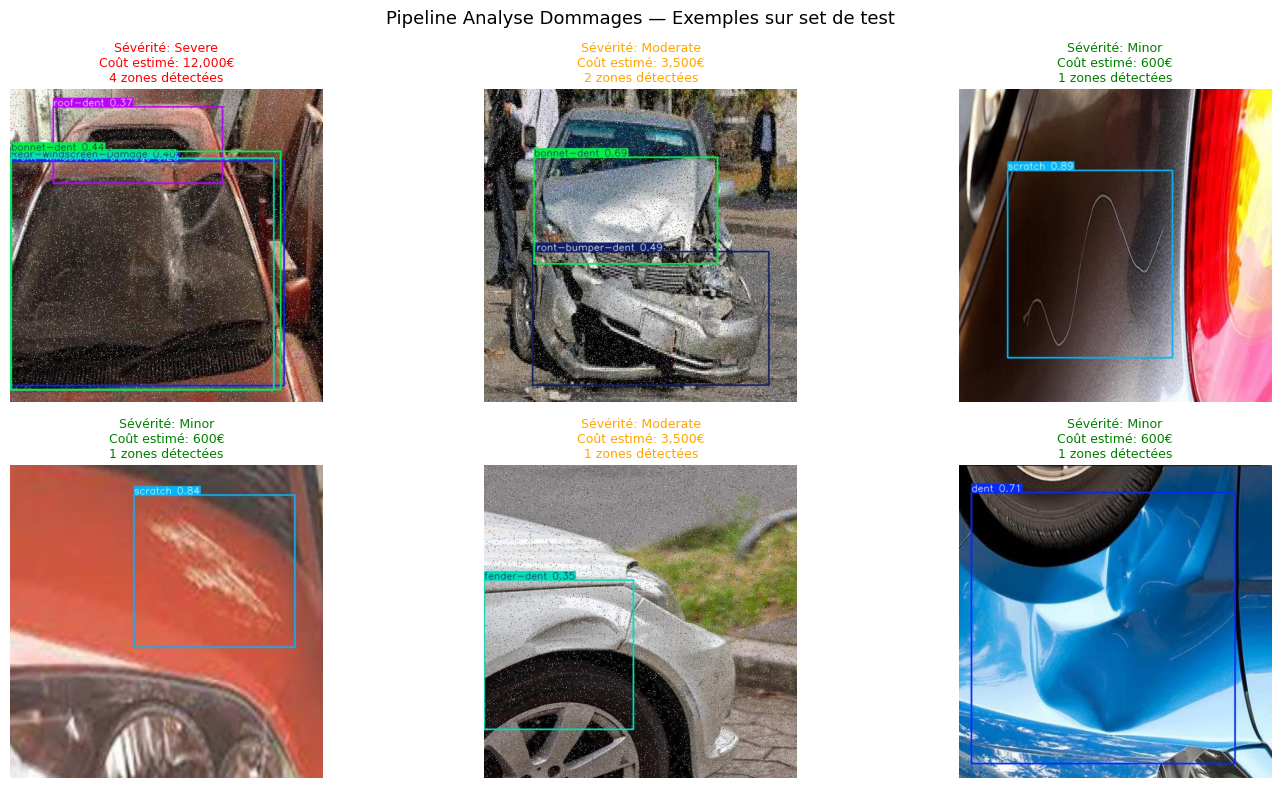

In [10]:
# Test du pipeline sur les images du set de test
test_images = list((Path(DATASET_PATH) / 'test' / 'images').glob('*.jpg'))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, img_path in enumerate(test_images):
    report = analyze_vehicle_damage(str(img_path))

    # Afficher l'image annotée
    img_b64 = report['annotated_image_b64']
    img_bytes = base64.b64decode(img_b64)
    img = Image.open(BytesIO(img_bytes))
    axes[i].imshow(img)

    severity = report['overall_severity']
    cost = report['cost_estimate']
    n_det = report['n_damage_zones']

    color_map = {'Minor': 'green', 'Moderate': 'orange',
                 'Severe': 'red', 'Total Loss': 'darkred',
                 'No Damage Detected': 'gray'}

    axes[i].set_title(
        f"Sévérité: {severity}\n"
        f"Coût estimé: {cost.get('central',0):,}€\n"
        f"{n_det} zones détectées",
        color=color_map.get(severity, 'black'),
        fontsize=9
    )
    axes[i].axis('off')

plt.suptitle('Pipeline Analyse Dommages — Exemples sur set de test', fontsize=13)
plt.tight_layout()
plt.show()

In [24]:
from google.colab import files
from PIL import Image
import base64
from io import BytesIO

# =========================
# 1. UPLOAD IMAGES
# =========================
uploaded = files.upload()

results_all = []

for filename in uploaded.keys():

    print(f"\n Traitement : {filename}")

    # =========================
    # 2. LOAD IMAGE
    # =========================
    img = Image.open(filename).convert("RGB")

    # =========================
    # 3. SAVE CLEAN VERSION
    # =========================
    clean_path = f"/content/{filename}"
    img.save(clean_path)

    # =========================
    # 4. INFERENCE MODEL
    # =========================
    report = analyze_vehicle_damage(clean_path)

    # =========================
    # 5. PRINT RESULTS
    # =========================
    print(f" Dégâts détectés : {report['n_damage_zones']}")
    print(f" Sévérité        : {report['overall_severity']}")
    print(f" Coût estimé     : {report['cost_estimate']['central']:,} €")

    results_all.append({
        "image": filename,
        "zones": report['n_damage_zones'],
        "severity": report['overall_severity'],
        "cost": report['cost_estimate']['central']
    })

# =========================
# 6. SUMMARY TABLE
# =========================
print("\n===== RÉSUMÉ GLOBAL =====")
for r in results_all:
    print(r)

Saving images (5).jpg to images (5).jpg

 Traitement : images (5).jpg
 Dégâts détectés : 1
 Sévérité        : Moderate
 Coût estimé     : 3,500 €

===== RÉSUMÉ GLOBAL =====
{'image': 'images (5).jpg', 'zones': 1, 'severity': 'Moderate', 'cost': 3500}


Distribution des sévérités prédites (100 images test) :
severity
Moderate              42
Minor                 40
No Damage Detected     7
Severe                 6
Total Loss             5
Name: count, dtype: int64

Coût moyen estimé : 3,680€
Coût médian estimé: 3,500€


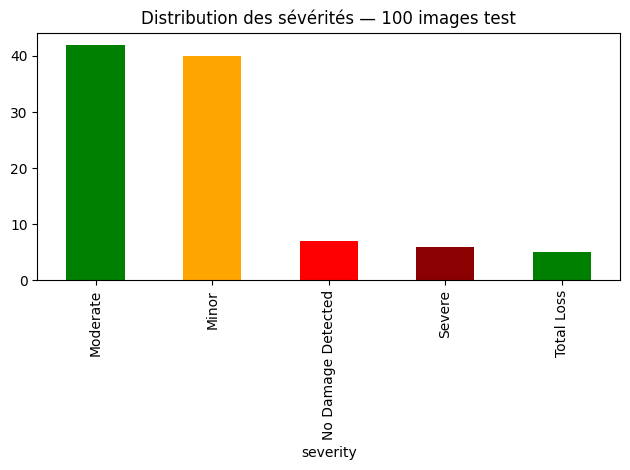

In [25]:
# Évaluation sur tout le set de test avec mapping sévérité
results_severity = []

for img_path in list((Path(DATASET_PATH) / 'test' / 'images').glob('*.jpg'))[:100]:
    report = analyze_vehicle_damage(str(img_path))
    results_severity.append({
        'image': img_path.name,
        'severity': report['overall_severity'],
        'n_zones': report['n_damage_zones'],
        'cost_central': report['cost_estimate'].get('central', 0)
    })

df_results = pd.DataFrame(results_severity)

print("Distribution des sévérités prédites (100 images test) :")
print(df_results['severity'].value_counts())
print(f"\nCoût moyen estimé : {df_results['cost_central'].mean():,.0f}€")
print(f"Coût médian estimé: {df_results['cost_central'].median():,.0f}€")

# Visualisation
df_results['severity'].value_counts().plot(
    kind='bar', color=['green','orange','red','darkred'],
    title='Distribution des sévérités — 100 images test'
)
plt.tight_layout()
plt.show()

In [26]:
# Impact du seuil de confiance sur le nombre de détections
thresholds = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
sample_img = str(test_images[0])

results_conf = []
for conf in thresholds:
    r = analyze_vehicle_damage(sample_img, conf_threshold=conf)
    results_conf.append({
        'conf_threshold': conf,
        'n_detections': r['n_damage_zones'],
        'severity': r['overall_severity']
    })

df_conf = pd.DataFrame(results_conf)
print(df_conf.to_string(index=False))

 conf_threshold  n_detections           severity
           0.15             4             Severe
           0.20             4             Severe
           0.25             4             Severe
           0.30             3             Severe
           0.35             3             Severe
           0.40             2             Severe
           0.50             0 No Damage Detected


## Bloc 8 — Connexion Module 2 : détection d'incohérence fraude

**La feature différenciante de SIAP** : croiser l'analyse visuelle avec
la déclaration du sinistre pour détecter les incohérences.

Exemple concret :
- Client déclare : 'scratch léger, montant estimé 200€'
- Photo montre : damaged-windscreen + Major-Rear-Bumper-Dent → Severe
→ Incohérence détectée → score fraude augmenté automatiquement

In [13]:
def check_fraud_coherence(
    visual_report: dict,
    declared_severity: str,
    declared_amount: float
) -> dict:
    """
    Croise l'analyse visuelle avec la déclaration du sinistre.
    Retourne un score d'incohérence et des alertes détaillées.

    Args:
        visual_report     : sortie de analyze_vehicle_damage()
        declared_severity : sévérité déclarée par le client ('Minor'/'Moderate'/'Severe')
        declared_amount   : montant réclamé en euros

    Returns:
        dict avec coherence_score (0-100), alerts, recommendation
    """
    alerts = []
    incoherence_score = 0

    visual_severity = visual_report['overall_severity']
    cost_estimate = visual_report['cost_estimate']

    # ── Test 1 : sévérité visuelle vs déclarée ──────────────
    if visual_severity != 'No Damage Detected':
        visual_order = SEVERITY_ORDER.get(visual_severity, 0)
        declared_order = SEVERITY_ORDER.get(declared_severity, 0)

        if visual_order > declared_order + 1:
            gap = visual_order - declared_order
            incoherence_score += min(40, gap * 15)
            alerts.append(
                f"Sévérité visuelle ({visual_severity}) supérieure "
                f"à la déclaration ({declared_severity}) de {gap} niveaux"
            )

    # ── Test 2 : montant déclaré vs fourchette estimée ──────
    if visual_severity not in ('No Damage Detected', 'Total Loss'):
        est_min = cost_estimate.get('min', 0)
        est_max = cost_estimate.get('max', 0)
        est_central = cost_estimate.get('central', 0)

        if declared_amount > est_max * 1.5:
            ratio = declared_amount / est_central
            incoherence_score += min(35, int((ratio - 1) * 20))
            alerts.append(
                f"Montant déclaré ({declared_amount:,.0f}€) très supérieur "
                f"à l'estimation visuelle ({est_min:,}-{est_max:,}€)"
            )
        elif declared_amount < est_min * 0.3 and declared_amount > 0:
            incoherence_score += 15
            alerts.append(
                f"Montant déclaré ({declared_amount:,.0f}€) très inférieur "
                f"à l'estimation minimale ({est_min:,}€) — sous-déclaration ?"
            )

    # ── Test 3 : pas de dégâts visuels mais sinistre déclaré
    if not visual_report['damage_detected'] and declared_amount > 500:
        incoherence_score += 30
        alerts.append(
            f"Aucun dégât détecté visuellement mais montant déclaré "
            f"de {declared_amount:,.0f}\u20ac"
        )

    incoherence_score = min(100, incoherence_score)

    if incoherence_score >= 60:
        recommendation = 'INVESTIGATION_REQUIRED'
    elif incoherence_score >= 30:
        recommendation = 'MANUAL_REVIEW'
    else:
        recommendation = 'AUTO_APPROVE'

    return {
        'incoherence_score': incoherence_score,
        'visual_severity': visual_severity,
        'declared_severity': declared_severity,
        'visual_cost_estimate': cost_estimate,
        'declared_amount': declared_amount,
        'alerts': alerts,
        'recommendation': recommendation,
        'fraud_flag': incoherence_score >= 60
    }

# ── Test avec un cas d'incohérence typique ──────────────────
print("TEST 1 — Cas cohérent :")
sample_img = str(test_images[0])
visual = analyze_vehicle_damage(sample_img)
coherence = check_fraud_coherence(
    visual,
    declared_severity='Moderate',
    declared_amount=3500.0
)
print(f"  Sévérité visuelle : {coherence['visual_severity']}")
print(f"  Score incohérence : {coherence['incoherence_score']}")
print(f"  Recommandation    : {coherence['recommendation']}")
print(f"  Alertes           : {coherence['alerts']}")

print("\nTEST 2 — Cas suspect (montant déclaré x5) :")
coherence2 = check_fraud_coherence(
    visual,
    declared_severity='Minor',   # déclare Minor alors que visuel = Severe
    declared_amount=50000.0      # montant x10
)
print(f"  Score incohérence : {coherence2['incoherence_score']}")
print(f"  Recommandation    : {coherence2['recommendation']}")
print(f"  Alertes           : {coherence2['alerts']}")

TEST 1 — Cas cohérent :
  Sévérité visuelle : Severe
  Score incohérence : 0
  Recommandation    : AUTO_APPROVE
  Alertes           : []

TEST 2 — Cas suspect (montant déclaré x5) :
  Score incohérence : 65
  Recommandation    : INVESTIGATION_REQUIRED
  Alertes           : ['Sévérité visuelle (Severe) supérieure à la déclaration (Minor) de 2 niveaux', "Montant déclaré (50,000€) très supérieur à l'estimation visuelle (5,000-20,000€)"]


## Bloc 9 — Checklist de validation actuarielle

Avant d'intégrer dans FastAPI, vérifier :
- [ ] mAP@50 > 57.2% (dépasser le baseline Roboflow)
- [ ] Toutes les classes mappées dans SEVERITY_MAPPING
- [ ] Pipeline retourne une image annotée en base64
- [ ] Détection d'incohérence fonctionne sur cas suspects
- [ ] Pas de crash sur image sans dégâts détectés

In [14]:
print("=" * 55)
print("VALIDATION ACTUARIELLE — Module 4")
print("=" * 55)

checks = {
    f'mAP@50 > 57.2% (baseline) : {map50*100:.1f}%': map50 > 0.572,
    f'Rappel > 50% : {recall*100:.1f}%': recall > 0.50,
    f'Précision > 55% : {precision*100:.1f}%': precision > 0.55,
    f'Toutes classes mappées': len(unmapped) == 0,
    f'Pipeline retourne image annotée': 'annotated_image_b64' in visual,
    f'Détection incohérence fraude': coherence2['fraud_flag'],
}

all_ok = True
for check, result in checks.items():
    status = 'oui' if result else 'non'
    print(f"{status} {check}")
    if not result:
        all_ok = False

print()
if all_ok:
    print(" Module 4 validé — prêt pour l'intégration FastAPI")
else:
    print("  Points à corriger avant intégration")

VALIDATION ACTUARIELLE — Module 4
oui mAP@50 > 57.2% (baseline) : 59.9%
oui Rappel > 50% : 62.9%
oui Précision > 55% : 77.3%
oui Toutes classes mappées
oui Pipeline retourne image annotée
oui Détection incohérence fraude

 Module 4 validé — prêt pour l'intégration FastAPI


## Bloc 10 — Export des artifacts pour FastAPI

In [27]:
import shutil
os.makedirs('cv_artifacts', exist_ok=True)

# 1. Meilleur modèle YOLO
shutil.copy('/content/runs/detect/siap_cv/car_damage_v1/weights/best.pt', 'cv_artifacts/yolo_car_damage.pt')

# 2. Métadonnées de déploiement
cv_meta = {
    'model_file': 'yolo_car_damage.pt',
    'model_type': 'YOLOv8n',
    'dataset': 'car-damage by Skillfactory (Roboflow)',
    'n_classes': len(CLASS_NAMES),
    'class_names': CLASS_NAMES,
    'severity_mapping': SEVERITY_MAPPING,
    'cost_estimate': COST_ESTIMATE,
    'conf_threshold': 0.25,
    'iou_threshold': 0.45,
    'imgsz': 640,
    'performance': {
        'map50': float(map50),
        'map50_95': float(map50_95),
        'precision': float(precision),
        'recall': float(recall),
    },
    'fraud_coherence': {
        'investigation_threshold': 60,
        'review_threshold': 30,
    }
}

with open('cv_artifacts/cv_meta.json', 'w') as f:
    json.dump(cv_meta, f, indent=2)

# 3. Zipper pour téléchargement
shutil.make_archive('cv_artifacts', 'zip', 'cv_artifacts')

print("Artifacts exportés dans cv_artifacts/ :")
for f in os.listdir('cv_artifacts'):
    size = os.path.getsize(f'cv_artifacts/{f}')
    print(f"  {f} ({size/1024:.0f} KB)")

print("\nTélécharger cv_artifacts.zip :")
from google.colab import files
files.download('cv_artifacts.zip')

Artifacts exportés dans cv_artifacts/ :
  yolo_car_damage.pt (6115 KB)
  cv_meta.json (3 KB)

Télécharger cv_artifacts.zip :


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>